# Milestone 03 - Step 1: SSIM + MAE Structural Loss

Notebook 02 ended with a baseline MSE autoencoder scoring **25.61% image-AUROC** on `metal_nut` (below 50% = ranking inverted: normals scored higher than defects). This notebook retrains with a structural loss and measures whether the ranking improves.

**Hypothesis:** MSE rewards blurry reconstructions, so sharp outer edges carry the largest error. Adding SSIM penalises lost structure during training and should give sharper reconstructions.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

if Path.cwd().name == "notebooks":
    os.chdir("..")
project_root = Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

tf.random.set_seed(42)
np.random.seed(42)

from src.training.train_autoencoder import train_autoencoder
from src.data.loader import create_test_dataset
from src.inference.localization import (
    compute_reconstruction_error_map,
    generate_heatmap_and_overlay,
    calculate_image_anomaly_score,
)
print(f"Working Directory:  {project_root}")
print(f"TensorFlow Version: {tf.__version__}")

Working Directory:  d:\Data Science\projects\VisionGuard-AI
TensorFlow Version: 2.21.0


## 1. Train with SSIM + MAE loss on Metal Nut

In [2]:
CATEGORY = "metal_nut"
EPOCHS = 25
BATCH_SIZE = 16
SSIM_WEIGHT = 0.5   # 0.0 = pure MAE, 1.0 = pure SSIM

results = train_autoencoder(
    category=CATEGORY,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    learning_rate=1e-3,
    loss_type="ssim_mae",
    ssim_weight=SSIM_WEIGHT,
)
autoencoder = results["autoencoder"]
history = results["history"]

 VisionGuard AI - Autoencoder Training: [METAL_NUT]
 Target Resolution: (256, 256)
 Batch Size:        16
 Initial LR:        0.001
 Loss Strategy:     ssim_mae (ssim_weight=0.5)
 Model Checkpoint:  artifacts\models\autoencoder_metal_nut_ssim_mae_best.keras

Dataset partitions: 187 training samples | 33 validation samples

Epoch 1/25


d:\Data Science\projects\VisionGuard-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 753ms/step - loss: 0.5295 - mae: 0.2820
Epoch 1: val_loss improved from None to 0.47886, saving model to artifacts\models\autoencoder_metal_nut_ssim_mae_best.keras

Epoch 1: finished saving model to artifacts\models\autoencoder_metal_nut_ssim_mae_best.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 852ms/step - loss: 0.5295 - mae: 0.2820 - val_loss: 0.4789 - val_mae: 0.2765 - learning_rate: 0.0010
Epoch 2/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 751ms/step - loss: 0.4818 - mae: 0.2563
Epoch 2: val_loss improved from 0.47886 to 0.47345, saving model to artifacts\models\autoencoder_metal_nut_ssim_mae_best.keras

Epoch 2: finished saving model to artifacts\models\autoencoder_metal_nut_ssim_mae_best.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 802ms/step - loss: 0.4818 - mae: 0.2563 - val_loss: 0.4734 - val_mae: 0.2686 - learning_rate: 0.0010
Epoch 3/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 797ms/step - loss: 0.4609 - mae: 0.2368
Epoch 3: val_loss improved from 0.47345 to 0.46525, saving model 

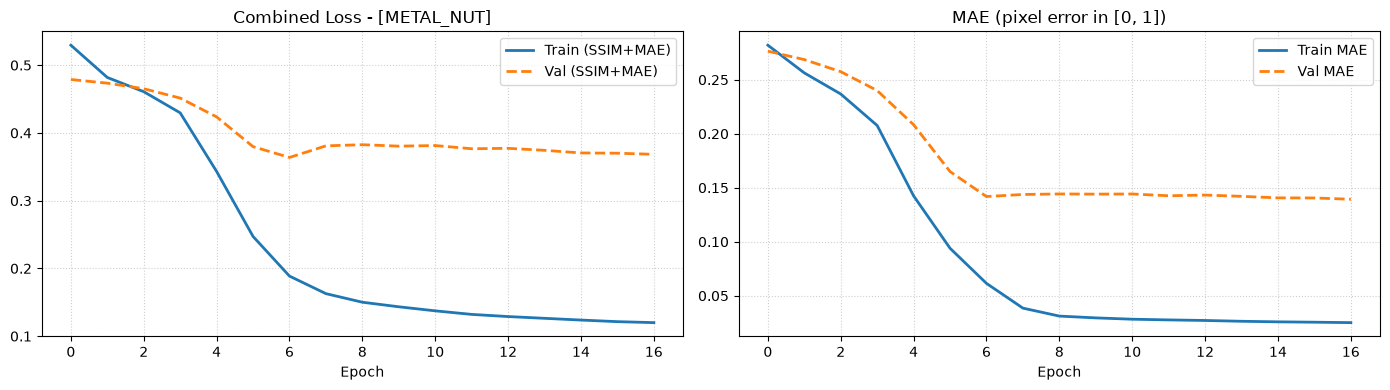

Best Val Loss: 0.36378 | Best Val MAE: 0.13935


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history["loss"], label="Train (SSIM+MAE)", linewidth=2)
axes[0].plot(history["val_loss"], label="Val (SSIM+MAE)", linewidth=2, linestyle="--")
axes[0].set_title(f"Combined Loss - [{CATEGORY.upper()}]"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True, linestyle=":", alpha=0.6)
axes[1].plot(history["mae"], label="Train MAE", linewidth=2)
axes[1].plot(history["val_mae"], label="Val MAE", linewidth=2, linestyle="--")
axes[1].set_title("MAE (pixel error in [0, 1])"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True, linestyle=":", alpha=0.6)
plt.tight_layout(); plt.show()
print(f"Best Val Loss: {min(history['val_loss']):.5f} | Best Val MAE: {min(history['val_mae']):.5f}")

## 2. Evaluate on the full test set (same protocol as notebook 02)

The test set is touched here only for benchmarking, never for training or threshold choice.

In [4]:
from sklearn.metrics import roc_auc_score

test_ds, test_labels, n_test = create_test_dataset(CATEGORY, batch_size=32)
imgs, lbls, masks = [], [], []
for b_img, b_lbl, b_mask in test_ds:
    imgs.append(b_img.numpy()); lbls.append(b_lbl.numpy()); masks.append(b_mask.numpy())
test_imgs = np.concatenate(imgs); test_lbls = np.concatenate(lbls); test_masks = np.concatenate(masks)

recons = autoencoder.predict(test_imgs, batch_size=32, verbose=0)
scores = np.array([
    calculate_image_anomaly_score(compute_reconstruction_error_map(test_imgs[i], recons[i]), method="top_k_mean")
    for i in range(len(test_imgs))
])

normal_scores, defect_scores = scores[test_lbls == 0], scores[test_lbls == 1]
auroc = roc_auc_score(test_lbls, scores)
BASELINE_AUROC = 0.2561   # MSE autoencoder, notebook 02

print(f"Normal  : n={len(normal_scores)}  mean={normal_scores.mean():.4f} (+/-{normal_scores.std():.4f})")
print(f"Defects : n={len(defect_scores)}  mean={defect_scores.mean():.4f} (+/-{defect_scores.std():.4f})")
print(f"Image AUROC  baseline (MSE): {BASELINE_AUROC*100:.2f}%  ->  SSIM+MAE: {auroc*100:.2f}%")

Normal  : n=22  mean=0.2820 (+/-0.0243)
Defects : n=93  mean=0.2675 (+/-0.0153)
Image AUROC  baseline (MSE): 25.61%  ->  SSIM+MAE: 30.21%


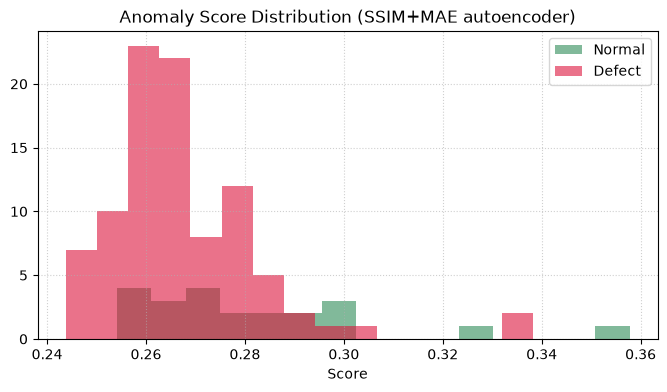

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(normal_scores, bins=15, alpha=0.6, label="Normal", color="seagreen")
plt.hist(defect_scores, bins=15, alpha=0.6, label="Defect", color="crimson")
plt.title("Anomaly Score Distribution (SSIM+MAE autoencoder)"); plt.xlabel("Score"); plt.legend(); plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

## 3. Does the edge problem persist?

Same diagnostic as notebook 02, Section 5: look at where the error lives on a **normal** part.

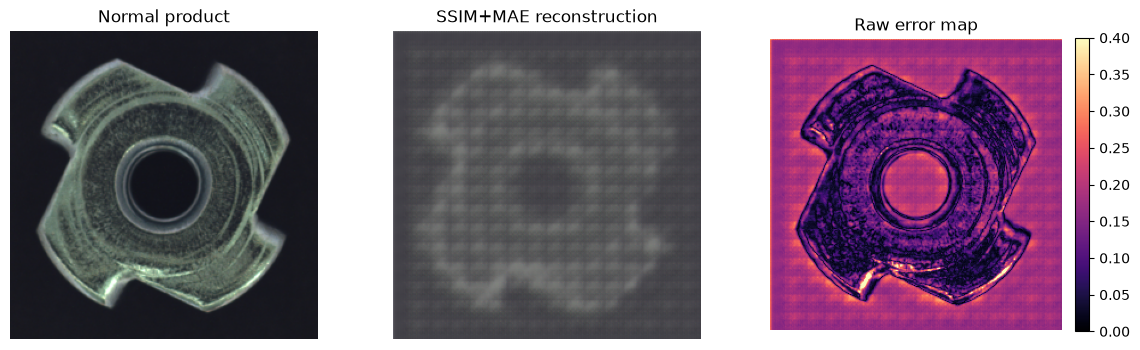

In [6]:
idx = np.where(test_lbls == 0)[0][0]
raw_err = np.mean(np.abs(test_imgs[idx] - recons[idx]), axis=-1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(test_imgs[idx]); axes[0].set_title("Normal product"); axes[0].axis("off")
axes[1].imshow(recons[idx]); axes[1].set_title("SSIM+MAE reconstruction"); axes[1].axis("off")
im = axes[2].imshow(raw_err, cmap="magma", vmin=0.0, vmax=0.4); axes[2].set_title("Raw error map"); axes[2].axis("off")
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04); plt.show()

## 4. Findings

_Fill in after running:_ AUROC change vs baseline, whether edge error is still dominant, and what that implies for **Step 2 (foreground / edge-masked scoring)**.